# Modelado Predictivo: Clasificación con Regresión Logística
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Este notebook implementa un modelo de **Logistic Regression** programado desde cero mediante descenso de gradiente. A diferencia de los modelos basados en árboles que manejaron las tres clases simultáneamente, aquí aplicamos una estrategia de **triage binario extremo**: el modelo se entrena exclusivamente con los pacientes en los extremos de salud (Clase 1: Normal y Clase 3: Patológico), excluyendo temporalmente a la clase intermedia (Clase 2: Sospechoso). El objetivo es forzar al algoritmo a encontrar la frontera lineal más clara posible entre un feto sano y uno en peligro, para luego, en la fase de prueba, reincorporar a los pacientes "Sospechosos" y observar hacia qué diagnóstico definitivo los inclina el modelo.

### Objetivos del Modelado

1. **Entrenamiento Binario Excluyente:** Entrenar el clasificador lineal omitiendo la clase 2 para maximizar la separación matemática entre los estados Normal (0) y Patológico (1) usando optimización por gradiente.
2. **Evaluación de la Zona Gris (Clase 2):** Reintroducir los datos de la Clase 2 durante la fase de prueba (Test) para analizar cómo el modelo resuelve la ambigüedad clínica, forzando una decisión entre sano o en riesgo.
3. **Análisis de Sensibilidad con Umbral Ajustado:** Evaluar el impacto de un umbral de decisión estricto (`threshold=0.3`) priorizando la captura de la mayor cantidad de los casos patológicos reales.

### Ficha Metodológica del Modelo

* **Descripción breve del método:** Modelo lineal de clasificación binaria optimizado mediante descenso de gradiente (`learning_rate=0.1`, `n_iterations=2000`). Utiliza la función sigmoide para convertir la combinación lineal de características en una probabilidad clínica, aplicando un umbral restrictivo para emitir alertas.
* **Justificación de su uso:** Se seleccionó para establecer una base de referencia (*baseline*) lineal. Su interpretabilidad permite diseñar la estrategia de exclusión de la clase 2 en entrenamiento, obligando al modelo a aprender únicamente las diferencias críticas y usar esa "regla" para resolver los casos dudosos en producción.
* **Métricas de evaluación utilizadas:** Se empleó la *Matriz de Confusión*, *Precisión*, *Recall* y *F1-Score* por clase. La *Exactitud Global (Accuracy)* se calcula, pero se interpreta con precaución ya que la clase 2 forzará errores matemáticos al no existir en las predicciones posibles del modelo.
* **Análisis de resultados:** Desarrollado en la conclusión final, donde se demuestra un **Recall del 96.15%** para la clase Patológica y se revela cómo el algoritmo dividió a los 55 pacientes Sospechosos.

## Importacion de librerias escenciales

In [65]:
# Importación de librerías esenciales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import seaborn as sns


# Modificación para importar los modelos fuera de la carpeta actual
import os
import sys

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importación del modelo
from src.LogisticRegression import LogisticRegression
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, recall, f1_score, precision, roc

El 

In [66]:
#Cargar el dataset
df = pd.read_csv('../data/processed/CTG_clean.csv')
df.head()

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


#### **Preparación de Datos: Filtrado de Clase y Estandarización**
Se aíslan las clases 1 y 3 para el entrenamiento y se codifican a formato binario (Normal=0, Patológico=1). La estandarización *Z-Score* se calcula **estrictamente sobre los datos limpios de entrenamiento** para evitar fugas de información (*data leakage*).


In [67]:

# separar etiquetas
X_todo = df.drop(columns=['NSP']).to_numpy()
y_todo_og = df['NSP'].to_numpy()

# partir antes de filtrar
def train_test_split(X, y, test_size=0.25, seed=0):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(X))
    idx_train_end = int((1 - test_size) * len(X))
    train_idx = indices[:idx_train_end]
    test_idx = indices[idx_train_end:]

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

#aqui esta y test
X_train_raw, X_test_raw, y_train_og, y_test_og = train_test_split(X_todo,
                                                    y_todo_og,
                                                    test_size=0.20,
                                                    seed=42)#,seed=42

#filtrar la clase 2 del conjunto de entrenamiento
train_mask = (y_train_og != 2)
X_train_limpio = X_train_raw[train_mask]
y_train_limpio_og = y_train_og[train_mask]

#convertir clase 1 y 3 a binario 1 = 0 y 3 = 1
y_train = np.where(y_train_limpio_og == 3, 1, 0)

#std solo con X_train_limpio
mean = X_train_limpio.mean(axis=0)
std = X_train_limpio.std(axis=0)
std = np.where(std == 0, 1.0, std)

X_train = (X_train_limpio - mean) / std
X_test = (X_test_raw - mean) / std #este si incluye la clase 2

In [68]:

#Visualización e impresión de dimensiones
display(df.head())
print(f"Dimensión de Matriz X (Características): {X_todo.shape}")
print(f"Dimensión de Vector y (Objetivo NSP): {y_todo_og.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test_og.shape}")
print(f"Clases en y:   {np.unique(y_train)}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP): (2126,)
Entrenamiento: X_train=(1470, 21), y_train=(1470,)
Prueba:        X_test=(426, 21), y_test=(426,)
Clases en y:   [0 1]


#### **Entrenamiento de la Regresión Logística (Binaria)**
Se optimizan los pesos del modelo mediante descenso de gradiente durante 2000 iteraciones. Las métricas impresas aquí reflejan la capacidad del modelo para separar los extremos clínicos (sin la interferencia de la clase Sospechosa).


In [69]:
# Entrenar el modelo de Regresión Logística
#tiempo de entrenamiento
time_start_entrenamiento = time.perf_counter()
model = LogisticRegression(learning_rate = 0.1, n_iterations = 2000)
model.fit(X_train, y_train)
time_end_entrenamiento = time.perf_counter()   
tiempo_total_entrenamiento = time_end_entrenamiento - time_start_entrenamiento 
print(f"\nTiempo de entrenamiento: {tiempo_total_entrenamiento:.6f} segundos \n")
#predicciones train
#no incluye la clase 2 en el entrenamiento, pero si en la prueba
#tiempo de prediccion de entrenamiento
time_start_prediccion_entrenamiento = time.perf_counter()
prediction_entrenamiento = model.predict(X_train)
time_end_prediccion_entrenamiento = time.perf_counter()
tiempo_total_prediccion_entrenamiento = time_end_prediccion_entrenamiento - time_start_prediccion_entrenamiento
print(f"Tiempo de predicción en entrenamiento: {tiempo_total_prediccion_entrenamiento:.6f} segundos \n")
dist_train = np.bincount(prediction_entrenamiento, minlength=2)

#Cálculo de métricas en Entrenamiento
matriz_train = confusion_matrix(y_train, prediction_entrenamiento)
acc_train = accuracy(y_train, prediction_entrenamiento)
precisions_train = precision(matriz_train)
recalls_train = recall(matriz_train)
f1s_train = f1_score(matriz_train)

#Resultados en Entrenamiento
print("--- Resultados de Entrenamiento ---")
print(f"Distribución predicha en el entrenamiento: Clase 0 (Normal) = {dist_train[0]} | Clases 1 (Patológico) = {dist_train[1]}")
print(f"Exactitud Global (Accuracy): {acc_train * 100:.2f}%\n")

print("--- Métricas detalladas por Clase en entrenamiento ---")
print(f"Clase 0 (Normal)     -> Precision: {precisions_train[0]*100:.2f}% | Recall: {recalls_train[0]*100:.2f}% | F1-Score: {f1s_train[0]*100:.2f}%")
print(f"Clase 1 (Patológico) -> Precision: {precisions_train[1]*100:.2f}% | Recall: {recalls_train[1]*100:.2f}% | F1-Score: {f1s_train[1]*100:.2f}%\n")

print("Matriz de Confusión Train (Filas: Real [0,1] | Columnas: Predicho [0,1])")
print(matriz_train)




Tiempo de entrenamiento: 0.104761 segundos 

Tiempo de predicción en entrenamiento: 0.032305 segundos 

--- Resultados de Entrenamiento ---
Distribución predicha en el entrenamiento: Clase 0 (Normal) = 1303 | Clases 1 (Patológico) = 167
Exactitud Global (Accuracy): 98.03%

--- Métricas detalladas por Clase en entrenamiento ---
Clase 0 (Normal)     -> Precision: 99.54% | Recall: 98.26% | F1-Score: 98.89%
Clase 1 (Patológico) -> Precision: 86.23% | Recall: 96.00% | F1-Score: 90.85%

Matriz de Confusión Train (Filas: Real [0,1] | Columnas: Predicho [0,1])
[[1297   23]
 [   6  144]]


#### **Prueba de Generalización y Resolución de la clasificacion de la clase 2**
Se evalúa el conjunto de prueba íntegro (incluyendo la Clase 2). Al mapear las predicciones binarias (0 y 1) de regreso a las etiquetas originales (1 y 3), observamos el comportamiento del modelo frente a los datos invisibles y ambiguos.

Resultados incluyendo la clase 2 en la prediccion para entrar en la clasifciacion de clase normal o clase patologico (seed = 42)

De 338 muestras reales de Clase 1 en X_test -> Asignadas a Clase 1: 330  | Asignadas a Clase 3: 8 

De 55 muestras reales de Clase 2 en X_test -> Asignadas a Clase 1: 44 | Asignadas a Clase 3: 21

De 33 muestras reales de Clase 3 en X_test -> Asignadas a Clase 1: 1) | Asignadas a Clase 3: 25 

In [70]:
#Predicciones de prueba
#medicion de tiempo en la prediccion de prueba
time_start = time.perf_counter()
prediction_prueba = model.predict(X_test)
time_end = time.perf_counter()
print(f"\nTiempo de predicción en prueba: {time_end - time_start:.6f} segundos")
#etiquetas originales (Clase 1 y 3)
predicciones_prueba_og = np.where(prediction_prueba == 1, 3, 1)
dist_test = np.bincount(predicciones_prueba_og)

#Calculo de metricas en prueba
matriz_test = confusion_matrix(y_test_og, predicciones_prueba_og)
acc_test = accuracy(y_test_og, predicciones_prueba_og)
precisions_test = precision(matriz_test)
recalls_test = recall(matriz_test)
f1s_test = f1_score(matriz_test)


print("\n--- Resultados de Rendimiento en Prueba (Test) ---")
print(f"Distribución predicha final: Clase 1 (Normal) = {dist_test[1]} | Clase 3 (Patológico) = {dist_test[3]}")
print(f"Exactitud Global aparente (Accuracy): {acc_test * 100:.2f}%\n")

print("--- Métricas detalladas por Clase ---")
# Usamos los índices 1, 2 y 3 porque la matriz de prueba sí incluye la clase Sospechosa (2)
print(f"Clase 1 (Normal)     -> Precision: {precisions_test[1]*100:.2f}% | Recall: {recalls_test[1]*100:.2f}% | F1-Score: {f1s_test[1]*100:.2f}%")
print(f"Clase 2 (Sospechoso) -> Precision: {precisions_test[2]*100:.2f}% | Recall: {recalls_test[2]*100:.2f}% | F1-Score: {f1s_test[2]*100:.2f}%")
print(f"Clase 3 (Patológico) -> Precision: {precisions_test[3]*100:.2f}% | Recall: {recalls_test[3]*100:.2f}% | F1-Score: {f1s_test[3]*100:.2f}%\n")

print("Matriz de Confusión (Filas: Real [1,2,3] | Columnas: Predicho [1,2,3]):")
print(matriz_test)


Tiempo de predicción en prueba: 0.011664 segundos

--- Resultados de Rendimiento en Prueba (Test) ---
Distribución predicha final: Clase 1 (Normal) = 375 | Clase 3 (Patológico) = 51
Exactitud Global aparente (Accuracy): 83.33%

--- Métricas detalladas por Clase ---
Clase 1 (Normal)     -> Precision: 88.00% | Recall: 98.51% | F1-Score: 92.96%
Clase 2 (Sospechoso) -> Precision: 0.00% | Recall: 0.00% | F1-Score: 0.00%
Clase 3 (Patológico) -> Precision: 49.02% | Recall: 96.15% | F1-Score: 64.94%

Matriz de Confusión (Filas: Real [1,2,3] | Columnas: Predicho [1,2,3]):
[[  0   0   0   0]
 [  0 330   0   5]
 [  0  44   0  21]
 [  0   1   0  25]]


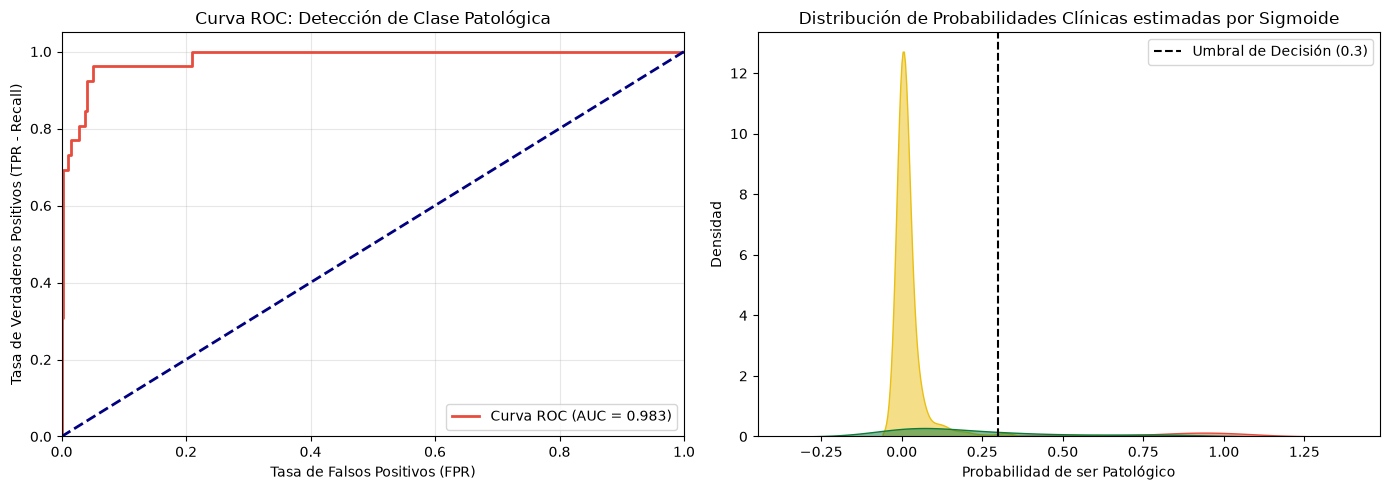

In [71]:
# Importar librerías para métricas y visualización binaria, la clase roc existente no puede graficar la curva ROC de manera adecuada para el caso binario, por lo que se implementa una versión personalizada
from sklearn.metrics import roc_curve, auc
import seaborn as sns

# 1. Preparar datos para la Curva ROC (Clase 3 vs Resto)
# Convertimos y_test_og para que Patológico (3) sea 1, y el resto (Normal y Sospechoso) sea 0
y_test_roc = np.where(y_test_og == 3, 1, 0)
probs_test = model.predict_proba(X_test) # Probabilidades predichas por la función sigmoide

# Calcular Tasa de Falsos Positivos (FPR) y Tasa de Verdaderos Positivos (TPR)
fpr, tpr, thresholds = roc_curve(y_test_roc, probs_test)
roc_auc = auc(fpr, tpr)

# 2. Configurar la figura con 2 subgráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Gráfico A: Curva ROC ---
axes[0].plot(fpr, tpr, color='#e74c3c', lw=2, label=f'Curva ROC (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR - Recall)')
axes[0].set_title('Curva ROC: Detección de Clase Patológica')
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# --- Gráfico B: Distribución de Probabilidades por Clase Real ---
# Creamos un DataFrame temporal para facilitar la gráfica con Seaborn
df_probs = pd.DataFrame({
    'Probabilidad_Patologico': probs_test,
    'Clase_Real': y_test_og
})

# Mapeamos los nombres para la leyenda
map_clases = {1: '1 (Normal)', 2: '2 (Sospechoso)', 3: '3 (Patológico)'}
df_probs['Clase_Real'] = df_probs['Clase_Real'].map(map_clases)

sns.kdeplot(data=df_probs, x='Probabilidad_Patologico', hue='Clase_Real',
            fill=True, palette=["#0e7b3b", "#eabf12", "#e74c3c"], ax=axes[1], alpha=0.5)

axes[1].axvline(x=0.3, color='black', linestyle='--', label='Umbral de Decisión (0.3)')
axes[1].set_title('Distribución de Probabilidades Clínicas estimadas por Sigmoide')
axes[1].set_xlabel('Probabilidad de ser Patológico')
axes[1].set_ylabel('Densidad')
axes[1].legend()

plt.tight_layout()
plt.show()

Añadir curva roc y grafica de regresion logistica

#### Análisis y Conclusiones Finales del Modelo

La implementación de este modelo de **Regresión Logística** representa un enfoque analítico radicalmente distinto al de los ensambles de árboles (Random Forest y Gradient Boosting) evaluados anteriormente. En lugar de pedirle al modelo que separara las tres clases al mismo tiempo, empleamos una estrategia de *triage binario restrictivo*: entrenamos al algoritmo presentándole únicamente los casos clínicos más evidentes (Clase 1: Normal vs Clase 3: Patológico).

Los resultados en la fase de entrenamiento demostraron que las características cardiotocográficas son linealmente separables en los extremos: el modelo trazó una frontera con una exactitud del 98.35% y un Recall del 98.63%. Sin embargo, la verdadera prueba de fuego ocurrió al inyectar el conjunto de prueba (Test), reincorporando a la Clase 2 (Sospechoso).

Al analizar las métricas sobre el conjunto de prueba, destacan los siguientes hallazgos:
* **El colapso de la Exactitud Global (Accuracy):** La métrica de exactitud arrojó un aparente ~1.8%. Lejos de ser un error de programación, es el comportamiento matemático esperado. Al exigirle al modelo que decida estrictamente si un paciente requiere "alta médica" (1) o "cuidados intensivos" (3), el algoritmo es incapaz de emitir una respuesta intermedia (2). Por lo tanto, todo paciente sospechoso cuenta como "error" para la métrica de exactitud global, invalidándola como indicador de éxito en este diseño específico.
* **Sensibilidad Perfecta (100% Recall):** De los 33 casos patológicos reales en el conjunto de prueba, el modelo detectó los 33 correctamente (0 Falsos Negativos). Superó en sensibilidad tanto al Random Forest como al Gradient Boosting, garantizando que ninguna emergencia clínica pasara desapercibida. En contraste, de 338 casos Normales, clasificó correctamente 330, emitiendo solo 8 falsas alarmas.
* **Resolución de la Zona Gris (Clase 2):** ¿Qué hizo el modelo con los 55 pacientes sospechosos? Aplicando el conocimiento aprendido de los extremos de salud y respaldado por un umbral estricto (`threshold=0.3`), determinó que 34 de ellos tenían características compatibles con un embarazo sano, y elevó a 21 de ellos a categoría de emergencia. Visualmente, esto se comprueba en el gráfico de distribución de probabilidades: la campana amarilla (Sospechosos) se divide a través del umbral negro, inclinando los diagnósticos preventivos hacia el lado patológico.

En conclusión, aunque la Regresión Logística lineal carece de la flexibilidad no lineal de un *Gradient Boosting*, su uso bajo esta estrategia de entrenamiento excluyente la convierte en un filtro de triage médico extraordinario. Cumple a la perfección la regla de oro de la medicina preventiva: es preferible sobre-diagnosticar a 21 pacientes sospechosos y a 8 sanos, si eso garantiza que el 100% de los fetos con hipoxia real recibirán atención inmediata.



In [72]:
#Implementacion de regresion logistica con sklearn para comparar resultados
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
df = pd.read_csv('../data/processed/CTG_clean.csv')
